## Import required libraries

In [1]:
import pandas as pd
import matplotlib.pyplot as plt 

## Regular expression pattern for validating variant identifiers

In [2]:
# \d+ = one or more digits only (no minus sign; "positive" interpreted as non-negative since position 0 occurs in the data)
# [ACGT]+ = one or more of the nucleotides A, C, G, T
regex_pattern = r'\d+:\d+:[ACGT]+:[ACGT]+'

## Pre-analysis: Inspection of raw data for missing values and invalid variant identifiers

## Import raw dataset

In [3]:
raw_df = pd.read_csv('human_genetic_annotations.txt', delimiter="\t", header=None)

## Print general information

In [4]:
raw_df.info(show_counts = True)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 13453286 entries, 0 to 13453285
Data columns (total 3 columns):
 #   Column  Non-Null Count     Dtype 
---  ------  --------------     ----- 
 0   0       13453286 non-null  object
 1   1       13453169 non-null  object
 2   2       13453158 non-null  object
dtypes: object(3)
memory usage: 307.9+ MB


**Conclusion**: Column names need to be assigned, as the columns are currently labelled 0, 1 and 2 (see column labelled "Column"), and missing values are present in the dataset.

## Add column names

In [5]:
raw_df.columns = ['variant_identifier', 'variant_unit', 'annotation']

## Missing data and Invalid variant identifier

**1.** Total Rows with missing values and invalid variant identifier 

In [6]:
# Create dataframe containing rows with missing values
missing_df = raw_df[raw_df.isna().any(axis=1)]

# Count rows with missing values
missing_rows = len(missing_df)

# Count rows with invalid variant identifiers
invalid_variant_rows = (~raw_df['variant_identifier'].str.fullmatch(regex_pattern)).sum()

print("Rows with missing values:", missing_rows)
print("Rows with invalid variant identifiers:", invalid_variant_rows)

Rows with missing values: 245
Rows with invalid variant identifiers: 4094


**2.** Inspect number of missing values per column

In [7]:
raw_df.isna().sum()

variant_identifier      0
variant_unit          117
annotation            128
dtype: int64

**3.** Check for potential patterns of missing values

In [8]:
# Check if consecutive missing-value rows are within 10 rows of each other using missing_df created above
missing_within_10 = (missing_df.index.to_series().diff() <= 10).any()

print("Missing values within 10 rows:", missing_within_10)

# check whether variant_unit and annotation are both missing in the same row
both_missing = raw_df[
    raw_df['variant_unit'].isna() & raw_df['annotation'].isna()
]

print("Rows with both variant_unit and annotation missing:", len(both_missing))

Missing values within 10 rows: False
Rows with both variant_unit and annotation missing: 0


**Conclusion**: 117 missing values in variant_unit and 128 in annotation. They are isolated: none lie within 10 rows of each other and none overlap. A further 4,094 rows have an invalid variant identifier. All 4,339 rows will be removed in the cleaning function.

##### Free memory by deleting objects that are no longer needed

In [9]:
del raw_df, missing_df, missing_rows, invalid_variant_rows, missing_within_10, both_missing

# Assessment Part 1
This section imports and cleans the dataset by addressing missing values and invalid variant identifiers, followed by basic validation and an initial exploration of the cleaned data.
***

## Definition of data cleaning function

In [10]:
def clean_hga_dataset(txt_file):
    '''
    Helper function to clean the human genetic annotation dataset.

    Params:
    -------
    txt_file: str
        File containing annotation of genetic variants observed in participants in large biobank.

    Returns:
    -------
    pd.DataFrame
        Cleaned Human Genetic annotation dataset.
    '''
    # No header row in the file, so header=None prevents using the first data row as column names
    df = pd.read_csv(txt_file, delimiter="\t", header=None)
    
    # add columns names
    df.columns = ['variant_identifier', 'variant_unit', 'annotation'] 

    # drop any rows of missing data 
    df = df.dropna()

    # keep rows with correct variant_identifier
    df = df[df.variant_identifier.str.fullmatch(regex_pattern)] 


    # casting
    df = df.assign(annotation=lambda x: pd.Categorical(x['annotation']),
                   variant_unit=lambda x: pd.Categorical(x['variant_unit']))

    return df

## Import dataset

In [11]:
df = clean_hga_dataset('human_genetic_annotations.txt')

## Checking for missing values

In [12]:
df.isna().sum()

variant_identifier    0
variant_unit          0
annotation            0
dtype: int64

**Conclusion**: No missing values are present in the dataset.

## Print general information

In [13]:
df.info(show_counts = True) # show_countr = True to display missing values

<class 'pandas.core.frame.DataFrame'>
Index: 13448947 entries, 0 to 13453285
Data columns (total 3 columns):
 #   Column              Non-Null Count     Dtype   
---  ------              --------------     -----   
 0   variant_identifier  13448947 non-null  object  
 1   variant_unit        13448947 non-null  category
 2   annotation          13448947 non-null  category
dtypes: category(2), object(1)
memory usage: 244.0+ MB


## Inspecting the first and last entries

In [14]:
df.head()

,variant_identifier,variant_unit,annotation
0,1:25223376:T:TA,coding_SYF2_ENST00000236273,hc_lof
1,1:25223376:T:TA,coding_SYF2_ENST00000354361,hc_lof
2,1:25223421:G:A,coding_SYF2_ENST00000236273,hc_lof
3,1:25223421:G:A,coding_SYF2_ENST00000354361,hc_lof
4,1:25225000:A:ACTGTTTTTCCAGATCTATGACCATCCTGTCAA...,coding_SYF2_ENST00000236273,hc_lof


In [15]:
df.tail()

,variant_identifier,variant_unit,annotation
13453281,4:26999996:T:A,regulatory_chr4_26999000_27000000,constrained
13453282,4:26999996:T:A,regulatory_chr4_26999000_27000000,constrained
13453283,4:26999996:T:A,regulatory_chr4_26999000_27000000,constrained
13453284,4:26999996:T:A,regulatory_chr4_26999000_27000000,constrained
13453285,4:26999996:T:A,regulatory_chr4_26999000_27000000,constrained


## Number of unique values per column

In [16]:
for col in df:
    print(f'{col}: {df[col].nunique()}')

variant_identifier: 2340476
variant_unit: 7078
annotation: 9


**Note**: The output is used in the report.

## Inspection of annotation categories

In [17]:
for annotation in df['annotation'].unique():
    print(annotation)

hc_lof
synonymous
missense_cadd_less_25
missense_cadd_over_25
intron_splice_AI_050_donor_gain
intron_splice_AI_050_donor_loss
upstream_gerp_over_2
upstream_jarvis_over_0.99
constrained


## Annotation frequency across the dataset

In [18]:
counts = df['annotation'].value_counts()
percent = (df['annotation'].value_counts(normalize=True) * 100).round(4)

pd.concat([counts, percent], axis=1)

,count,proportion
annotation,,
constrained,13068279,97.1695
upstream_jarvis_over_0.99,137040,1.0190
missense_cadd_less_25,86858,0.6458
synonymous,58648,0.4361
missense_cadd_over_25,39259,0.2919
upstream_gerp_over_2,38393,0.2855
hc_lof,18245,0.1357
intron_splice_AI_050_donor_gain,1890,0.0141
intron_splice_AI_050_donor_loss,335,0.0025


**Note**: The output is used in the report.

## Function to create an extended dataframe

This reusable function adds the chromosome and position columns used  to calculate annotation frequencies by chromosome, while keeping the plotting function compatible with the three-column dataframe specified in the assignment.

In [19]:
def chrom_pos_df(df):
    '''
    Takes the original three-column dataframe and adds chromosome and position as new columns.
    
    Params:
    -------
    df: pd.DataFrame
        Cleaned human genetic annotation dataset containing variant identifiers,
        variant units, and annotations.
     
    Returns:
    -------
    pd.DataFrame
        Dataframe with additional chromosome and position columns.

    '''
    df = df.copy() # create a copy to avoid overwriting the original dataframe
    df['chromosome'] = df.variant_identifier.str.extract(r'^(\d+):', # regex extracts chromosome from the start of the structured variant identifier
                                                        expand = False) 
    df['position'] = df.variant_identifier.str.extract(r':(\d+):', # regex extracts position between colons from the structured variant identifier
                                                      expand = False 
                                                      ).astype('int32') # use int32 to reduce memory usage


    return df

## Dataframe preparation for chromosomes 1 and 2

In [20]:
freq_df = chrom_pos_df(df)

## Identifying unique chromosomes

In [21]:
freq_df['chromosome'].unique()

array(['1', '2', '3', '4'], dtype=object)

**Conclusion**: The dataset contains chromosomes 1, 2, 3, and 4.

### Summary statistics of genomic positions across the dataset

In [22]:
freq_df[['position']].agg(['mean', 'median', 'min', 'max']).T.round(0).astype(int) # integer

,mean,median,min,max
position,25934144,25814134,25000002,26999997


**Conclusion**: The overall genomic position ranges from 25'000'002 to 26'999'997

### Annotation frequency for chromosomes 1 and 2

In [23]:
freq_1_2 = freq_df[(freq_df['chromosome'] == '1') | (freq_df['chromosome'] == '2')]

counts = freq_1_2.groupby('chromosome')['annotation'].value_counts()
percent = (freq_1_2.groupby('chromosome')['annotation'].value_counts(normalize=True) * 100).round(4)

pd.concat([counts, percent], axis=1)

count  proportion
chromosome annotation                                          
1          constrained                      2740052     94.0063
           upstream_jarvis_over_0.99          65433      2.2449
           missense_cadd_less_25              43400      1.4890
           synonymous                         26135      0.8966
           upstream_gerp_over_2               18608      0.6384
           missense_cadd_over_25              14380      0.4934
           hc_lof                              6029      0.2068
           intron_splice_AI_050_donor_gain      642      0.0220
           intron_splice_AI_050_donor_loss       75      0.0026
2          constrained                      3287876     97.0825
           upstream_jarvis_over_0.99          28333      0.8366
           missense_cadd_less_25              23226      0.6858
           synonymous                         17143      0.5062
           missense_cadd_over_25              15356      0.4534
           hc_lof                              9450      0.2790
           upstream_gerp_over_2                4651      0.1373
           intron_splice_AI_050_donor_gain      539      0.0159
           intron_splice_AI_050_donor_loss      108      0.0032

**Note**: The output is used in the report.

## Summary statistics of genomic positions by chromosome

In [24]:
freq_1_2.groupby(['chromosome'])['position'].agg(['mean', 'median', 'min', 'max']).round(0).astype(int) 

,mean,median,min,max
chromosome,,,,
1,26120794,26224373,25000002,26999997
2,25854287,25642848,25000003,26999000


**Conclusion**: No substantial differences are observed between the genomic position distributions of chromosomes 1 and 2 and the overall genomic position distribution.

##### Free memory by deleting objects that are no longer needed

In [25]:
del freq_df, freq_1_2, counts, percent

# Assessment Part 2
This section plots each type of annotation as a function of the position on the chromosome, with one plot per chromosome.
***

In [26]:
# Map original annotation values to readable display labels
annotation_labels = {
    'hc_lof': 'HC LoF',
    'synonymous': 'Synonymous',
    'missense_cadd_less_25': 'Missense CADD < 25',
    'missense_cadd_over_25': 'Missense CADD > 25',
    'intron_splice_AI_050_donor_gain': 'Intron SpliceAI ≥ 0.50 Donor Gain',
    'intron_splice_AI_050_donor_loss': 'Intron SpliceAI ≥ 0.50 Donor Loss',
    'upstream_gerp_over_2': 'Upstream GERP > 2',
    'upstream_jarvis_over_0.99': 'Upstream JARVIS > 0.99',
    'constrained': 'Constrained'
}

# Define one colour for each annotation subplot
colours = ['tab:blue', 'tab:orange', 'tab:green', 'tab:red', 'tab:purple',
           'tab:brown', 'tab:pink', 'tab:gray', 'tab:olive']


def plot_annotation_histograms(df, chromosome_number):
    '''
    Plot the distribution of each variant annotation by position for a selected
    chromosome, as one histogram per annotation on a shared position axis.

    Params:
    -------
    df: pd.DataFrame
        Cleaned human genetic annotation dataset containing variant identifiers,
        variant units, and annotations.
    chromosome_number: str or int
        Chromosome number to be plotted.
    '''
    # Filter by chromosome before further processing, f-string: inserts the value of chromosome_number
    df_single = df[df['variant_identifier'].str.startswith(f'{chromosome_number}:')]

    # Extract chromosome and position from variant_identifier and create two columns with the already existing function chrom_pos_df
    df_single = chrom_pos_df(df_single)

    # Create nine vertically stacked subplots with a shared x-axis
    fig, axes = plt.subplots(nrows=9, sharex=True, figsize=(12, 10))

    # # Loop through the annotation_labels dictionary and plot the position distribution for each annotation
    i = 0
    for annotation, label in annotation_labels.items():
        subset = df_single[df_single['annotation'] == annotation]
        # f-string: inserts the label and the number of variants into the legend text
        axes[i].hist(subset['position'], bins=100, color=colours[i],
                     label=f'{label} (n = {len(subset):,})') 
        axes[i].legend(loc='upper left')
        i += 1

    # Set y label on the middle subplot (centred) and x label on the bottom subplot
    axes[4].set_ylabel('Number of variants', fontsize=12, fontweight='bold')
    axes[8].set_xlabel(f'Chromosome {chromosome_number} position (bp)', fontsize=12, fontweight='bold')

    # Improve spacing for readability
    plt.tight_layout()

    # Save plot
    plt.savefig(f'Chromosome_{chromosome_number}_plot.png')
    
    # Display the plot
    plt.show()



## Visualisation of annotation frequencies for chromosomes 1–4 

Each chromosome is represented in a separate figure, which is saved as a PNG file.

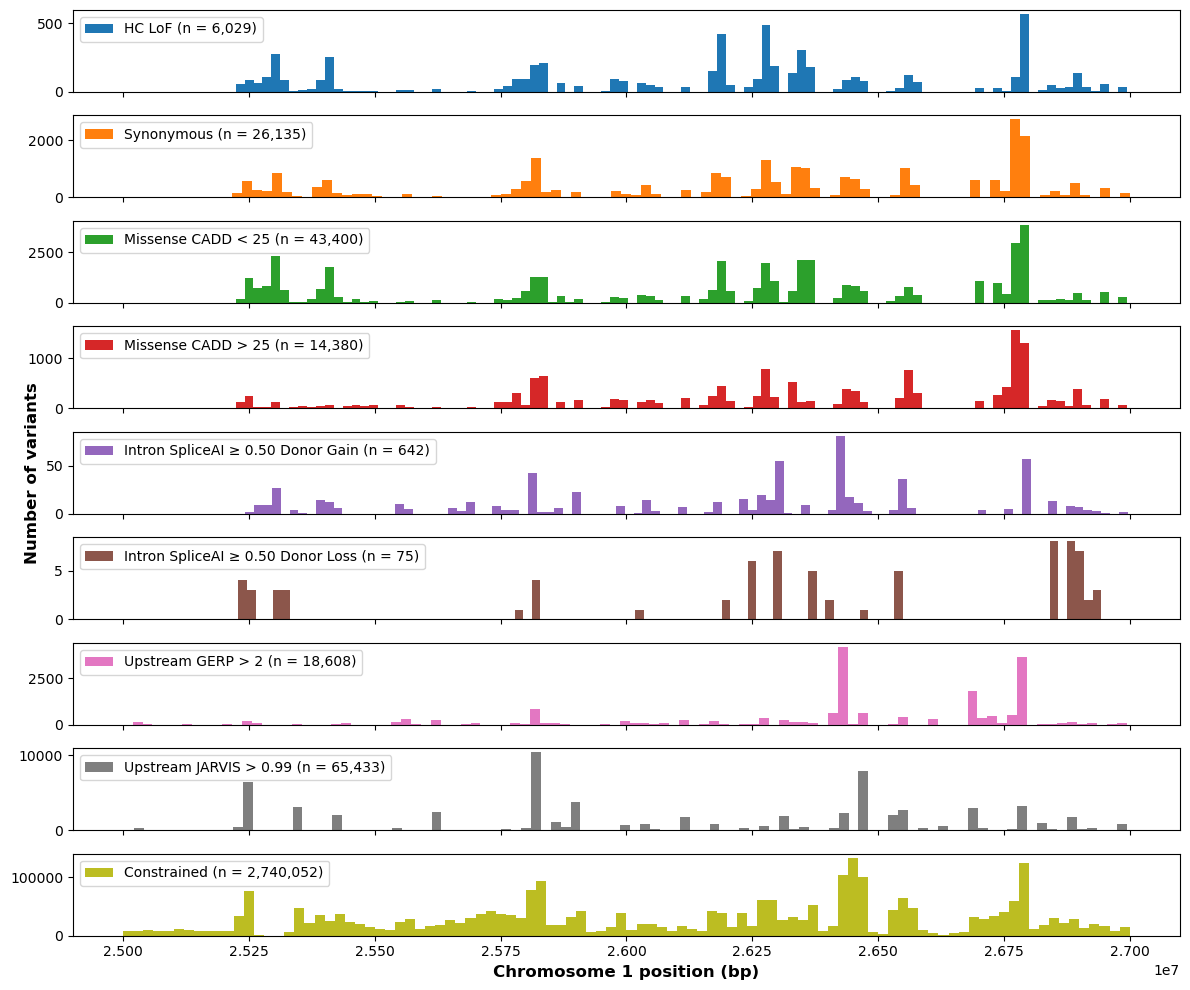

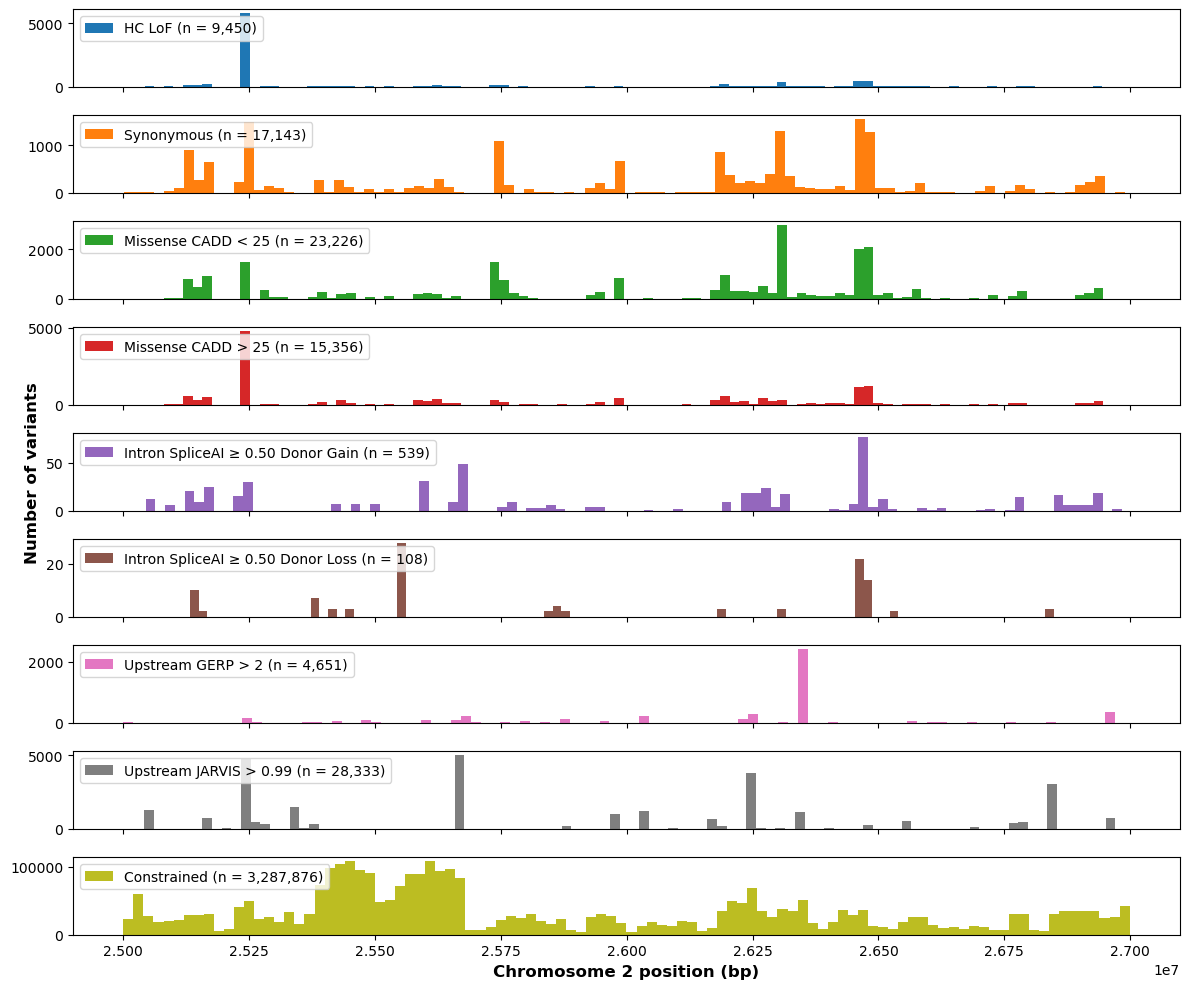

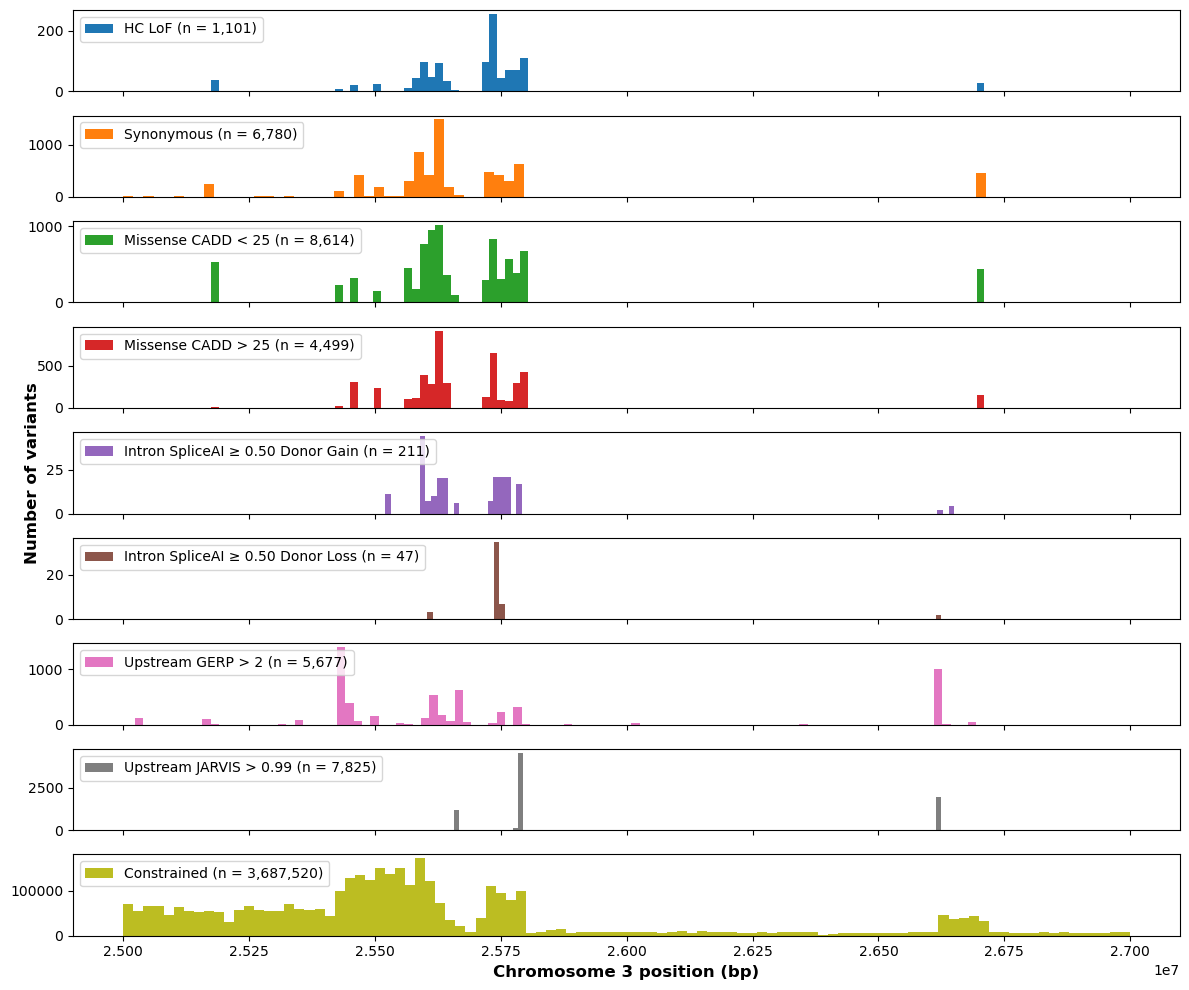

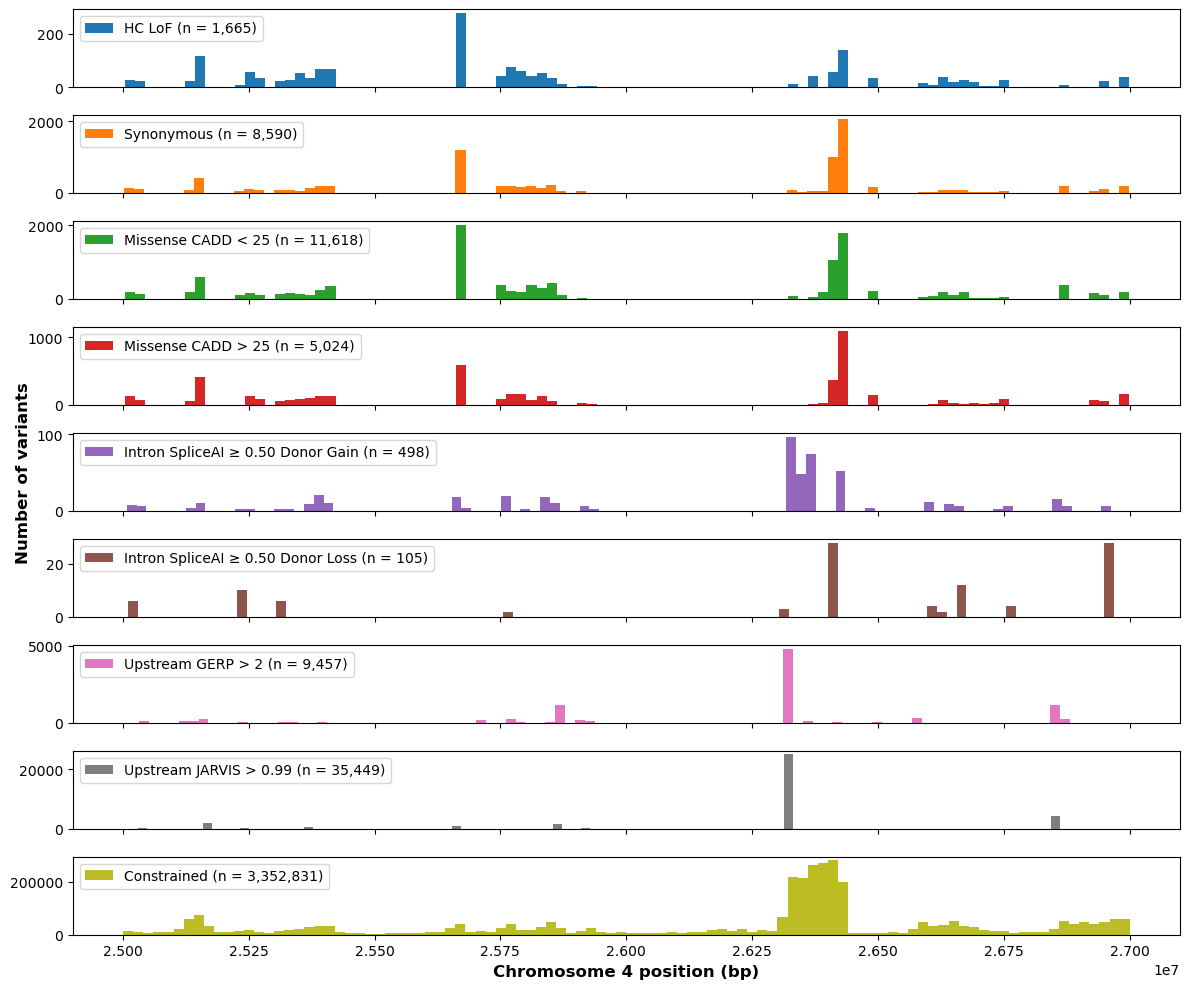

In [27]:
for chrom in [1, 2, 3, 4]:        
    plot_annotation_histograms(df, chrom)

**Note**: The histograms for chromosomes 1 and 2 are included in the report.

# Assessment Part 3
Each variant does not have a unique annotation within each unit. This section produces a new version of the original DataFrame where each variant has a “unique” annotation within each unit.
***

## Grouping of unique annotations

In [29]:
# Group the data by variant identifier and variant unit, retaining only observed groups. 
# Unique annotation within each combination are joined using an ampersand (&).
unique = (
    df.groupby(
        ["variant_identifier", "variant_unit"],
        observed=True
    )["annotation"]
    .unique()
    .apply(lambda x: "&".join(x))
    .reset_index()  # Restore the grouping variables as regular DataFrame columns
)

## Verification of annotation concatenation using ampersands (&)

In [47]:
unique[unique['annotation'].str.contains('&')]

,variant_identifier,variant_unit,annotation
6361,1:25018463:C:A,regulatory_chr1_25018000_25019000,synonymous&constrained
6787,1:25022344:C:T,proximal_MIR4425_ENST00000580572,upstream_gerp_over_2&upstream_jarvis_over_0.99
6788,1:25022346:G:A,proximal_MIR4425_ENST00000580572,upstream_gerp_over_2&upstream_jarvis_over_0.99
6793,1:25022362:T:G,proximal_MIR4425_ENST00000580572,upstream_gerp_over_2&upstream_jarvis_over_0.99
6794,1:25022368:G:T,proximal_MIR4425_ENST00000580572,upstream_gerp_over_2&upstream_jarvis_over_0.99
...,...,...,...
2641082,4:26989141:G:A,regulatory_chr4_26989000_26990000,constrained&synonymous
2641788,4:26991060:A:G,regulatory_chr4_26991000_26992000,constrained&synonymous
2642767,4:26993627:T:C,regulatory_chr4_26993000_26994000,constrained&synonymous
2643071,4:26994433:G:A,regulatory_chr4_26994000_26995000,constrained&synonymous


**Conclusion**: Variant-unit combinations with multiple annotations have been successfully joined using an ampersand (&).

## Descriptive Statistics of the reduced dataset

In [48]:
n_original = len(df)                                        # rows before collapsing
n_unique = len(unique)                                      # unique variant-unit combinations
reduction_pct = (1 - n_unique / n_original) * 100           # % reduction in rows

n_multi = unique['annotation'].str.contains('&').sum()      # variants with more than one annotation
multi_pct = n_multi / n_unique * 100

print(f"Original rows:{n_original:,}")
print(f"Unique variant-unit combinations: {n_unique:,}")
print(f"Reduction: {reduction_pct:.2f}%")
print(f"Variants with >1 annotation: {n_multi:,} ({multi_pct:.2f}%)")

Original rows:13,448,947
Unique variant-unit combinations: 2,645,383
Reduction: 80.33%
Variants with >1 annotation: 9,333 (0.35%)


**Note**: The output is used in the report

## Exporting the unique human genetic annotations to a .txt file

In [49]:
unique.to_csv("human_genetic_annotations_unique.txt", sep="\t", na_rep="NA", index=False)

**Note**: The .txt file will be submitted as part of the Assessment 2 documentation.